# CorporateRisk: corporate credit health check, walkthrough

This notebook runs the same functions as the dashboard, step by step.

> **Data notice:** unless you have created `data/raw/company_financials.csv`, the companies below are **SYNTHETIC** (fictional) and exist only to demonstrate the method. The health score is an illustrative, rule-based summary, **not** a credit rating or a probability of default.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import pandas as pd
import matplotlib.pyplot as plt
from corporaterisk import config as C, data_loader as dl, data_validation as dv
from corporaterisk import financial_ratios as fr, financial_scoring as fs, altman_zscore as az
from corporaterisk import trend_analysis as ta, company_comparison as cc, stress_testing as stt
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)

## 1. Load and validate the statements
Every check is reported; nothing is corrected silently.

In [2]:
df = dl.load_financials(C.active_data_file())
print('Synthetic data:', dl.is_synthetic(df), '|', df['company'].nunique(), 'companies,', len(df), 'company-years')
findings = dv.validate_financials(df)
findings

Synthetic data: True | 4 companies, 20 company-years


,severity,company,fiscal_year,check,detail
0,WARNING,Orbit Aviation Services (Synthetic),2021,negative_equity,Equity is zero or negative (accumulated losses...
1,WARNING,Orbit Aviation Services (Synthetic),2022,negative_equity,Equity is zero or negative (accumulated losses...
2,WARNING,Orbit Aviation Services (Synthetic),2023,negative_equity,Equity is zero or negative (accumulated losses...
3,WARNING,Orbit Aviation Services (Synthetic),2024,negative_equity,Equity is zero or negative (accumulated losses...
4,WARNING,Orbit Aviation Services (Synthetic),2025,negative_equity,Equity is zero or negative (accumulated losses...


## 2. Ratios for one company
Debt means **interest-bearing borrowings** only; total liabilities also include payables and provisions. Undefined ratios carry a status instead of a fake zero.

In [3]:
ratios = fr.compute_ratios(df)
DEMO = 'Kestrel Infrastructure (Synthetic)'
company = DEMO if DEMO in set(df['company']) else df['company'].iloc[0]
cols = ['fiscal_year', 'current_ratio', 'debt_to_equity', 'interest_coverage', 'net_debt_to_ebitda',
        'operating_margin', 'fcf_to_debt']
ratios.loc[ratios['company'] == company, cols].round(3)

,fiscal_year,current_ratio,debt_to_equity,interest_coverage,net_debt_to_ebitda,operating_margin,fcf_to_debt
5,2021,1.440,1.317,2.182,2.970,0.160,0.014
6,2022,1.317,1.461,1.756,3.667,0.139,-0.021
7,2023,1.197,1.674,1.170,5.017,0.105,-0.013
8,2024,1.060,2.027,0.625,7.407,0.067,0.004
9,2025,0.923,2.752,0.109,12.931,0.014,0.003


In [4]:
# Hand check of interest coverage for the latest year: EBIT / interest expense
r = ratios[ratios['company'] == company].iloc[-1]
print(f'EBIT {r.ebit:,.1f} / interest {r.interest_expense:,.1f} = {r.ebit / r.interest_expense:.3f} '
      f'(library: {r.interest_coverage:.3f})')

EBIT 21.0 / interest 192.0 = 0.109 (library: 0.109)


## 3. Financial health score (illustrative)
Each ratio maps linearly to 0-100 between a weak and a strong anchor; dimensions are averaged; the weighted average gives the score. Weights: liquidity 20%, leverage 25%, profitability 20%, debt servicing 25%, cash flow 10%.

In [5]:
scores = fs.score_table(ratios)
scores[['company', 'fiscal_year', 'health_score', 'risk_category', 'weight_coverage']
       + [f'score_{d}' for d in C.DIMENSIONS]].round(2)

,company,fiscal_year,health_score,risk_category,weight_coverage,score_Liquidity,score_Leverage,score_Profitability,score_Debt Servicing,score_Cash Flow Strength
0,Alpha Manufacturing (Synthetic),2021,75.02,Healthy,1.0,80.60,79.12,72.54,72.71,64.31
1,Alpha Manufacturing (Synthetic),2022,84.27,Strong,1.0,87.78,84.97,81.30,87.37,73.67
2,Alpha Manufacturing (Synthetic),2023,90.97,Strong,1.0,96.83,90.60,83.95,96.08,81.45
3,Alpha Manufacturing (Synthetic),2024,92.23,Strong,1.0,99.04,93.78,82.28,97.20,82.21
4,Alpha Manufacturing (Synthetic),2025,93.48,Strong,1.0,100.00,95.61,83.42,98.56,82.55
5,Kestrel Infrastructure (Synthetic),2021,48.81,Elevated Risk,1.0,53.19,46.48,64.33,33.41,53.37
6,Kestrel Infrastructure (Synthetic),2022,39.76,Elevated Risk,1.0,40.77,41.85,52.73,24.33,45.16
7,Kestrel Infrastructure (Synthetic),2023,28.07,High Risk,1.0,29.99,35.55,31.33,10.40,43.22
8,Kestrel Infrastructure (Synthetic),2024,18.53,High Risk,1.0,19.11,26.38,10.72,7.16,41.82
9,Kestrel Infrastructure (Synthetic),2025,9.68,High Risk,1.0,10.06,11.12,1.81,4.34,34.38


## 4. Altman Z-score distress screen
The variant is chosen once per company (original Z for listed manufacturers, Z'' for non-manufacturers) and never mixed.

In [6]:
az.z_table(df)[['company', 'fiscal_year', 'variant', 'z_score', 'zone']].round(2)

,company,fiscal_year,variant,z_score,zone
0,Alpha Manufacturing (Synthetic),2021,original,4.72,Safe
1,Alpha Manufacturing (Synthetic),2022,original,5.35,Safe
2,Alpha Manufacturing (Synthetic),2023,original,5.88,Safe
3,Alpha Manufacturing (Synthetic),2024,original,6.17,Safe
4,Alpha Manufacturing (Synthetic),2025,original,6.67,Safe
5,Kestrel Infrastructure (Synthetic),2021,z_double_prime,2.88,Safe
6,Kestrel Infrastructure (Synthetic),2022,z_double_prime,2.53,Grey
7,Kestrel Infrastructure (Synthetic),2023,z_double_prime,2.07,Grey
8,Kestrel Infrastructure (Synthetic),2024,z_double_prime,1.49,Grey
9,Kestrel Infrastructure (Synthetic),2025,z_double_prime,0.75,Distress


## 5. Trends and deterioration signals

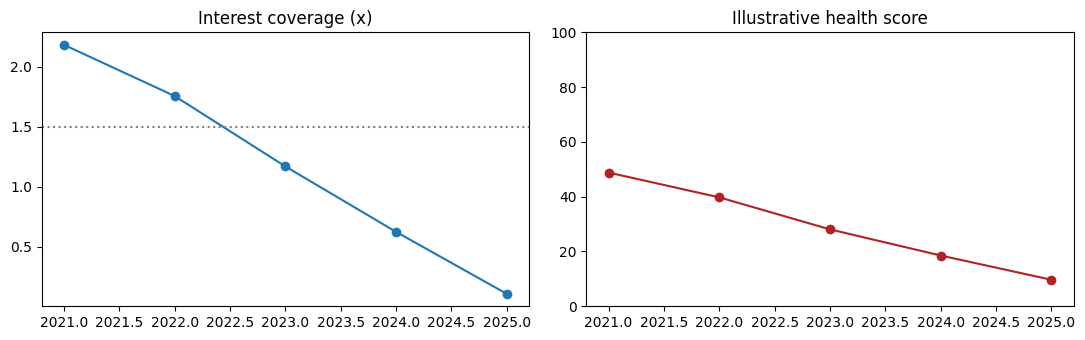

- Increasing leverage : Debt-to-equity rose in each of the last two years (1.67x -> 2.03x -> 2.75x).
- Declining interest coverage : Interest coverage fell in each of the last two years (1.17x -> 0.63x -> 0.11x).
- Weak liquidity : Current ratio is 0.92x (short-term obligations exceed short-term assets).
- Loss-making : Net profit is negative in the latest year.
- Falling health score : Health score fell from 28 to 10 over the period shown.


In [7]:
tf = ta.trend_frame(ratios, scores, company)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(tf['fiscal_year'], tf['interest_coverage'], marker='o')
ax[0].axhline(1.5, ls=':', c='grey'); ax[0].set_title('Interest coverage (x)')
ax[1].plot(tf['fiscal_year'], tf['health_score'], marker='o', c='firebrick')
ax[1].set_ylim(0, 100); ax[1].set_title('Illustrative health score')
plt.tight_layout(); plt.show()
for s in ta.deterioration_signals(ratios, scores, company, int(tf['fiscal_year'].max())):
    print('-', s['signal'], ':', s['evidence'])

## 6. Company comparison
Cross-sector comparisons can mislead; the sector column is always shown.

In [8]:
cc.comparison_table(ratios, scores, int(df['fiscal_year'].max()), formatted=True)

,Company,Sector,Year used,Current ratio,Quick ratio,Debt-to-equity,Net debt / EBITDA,Operating (EBIT) margin,Return on equity,Interest coverage (EBIT / interest),Operating cash flow / debt,Operating cash flow margin,Free cash flow / debt,Liquidity score,Leverage score,Profitability score,Debt Servicing score,Cash Flow Strength score,Health score,Category
0,Alpha Manufacturing (Synthetic),Industrial Manufacturing,2025,2.46x,1.57x,0.25x,0.22x,13.7%,18.3%,11.14x,90.2%,13.0%,46.6%,100.0,95.6,83.4,98.6,82.6,93.5,Strong
1,Kestrel Infrastructure (Synthetic),Infrastructure,2025,0.92x,0.70x,2.75x,12.93x,1.4%,-20.7%,0.11x,6.5%,8.6%,0.3%,10.1,11.1,1.8,4.3,34.4,9.7,High Risk
2,Lotus Consumer Goods (Synthetic),Consumer Goods,2025,1.69x,1.28x,0.00x,-0.97x,19.7%,37.5%,n/a (no debt/interest),n/a (no debt/interest),16.2%,n/a (no debt/interest),84.1,100.0,99.6,100.0,81.1,94.9,Strong
3,Orbit Aviation Services (Synthetic),Aviation Services,2025,0.16x,0.13x,n/m (adverse),n/m (adverse),-11.4%,n/m (adverse),-0.78x,-0.6%,-0.8%,-3.0%,0.0,0.0,0.0,0.0,8.8,0.9,High Risk


## 7. Stress test (illustrative)
Shocks hit revenue, EBITDA margin and interest; all items and ratios are recomputed. The balance sheet is held constant.

In [9]:
year = int(df.loc[df['company'] == company, 'fiscal_year'].max())
stt.run_stress(df, company, year)[['scenario', 'revenue', 'ebitda', 'net_profit', 'interest_coverage',
                                   'health_score', 'risk_category']].round(2)

,scenario,revenue,ebitda,net_profit,interest_coverage,health_score,risk_category
0,Base case,1450.0,145.00,-161.00,0.11,9.68,High Risk
1,Moderate stress,1305.0,104.40,-240.00,-0.09,8.16,High Risk
2,Severe stress,1087.5,54.38,-347.62,-0.24,6.57,High Risk


## Limitations
Illustrative weights and thresholds; no default data was used to calibrate them; ratios use annual figures only. See `docs/limitations.md`.